# Tugas Besar IoT — AIoT Early Warning Kelangsungan Hidup Tilapia
**Bagian 1: Audit dataset Montería + Digital Twin kolam tilapia**

Isi notebook:
1. **Setup & unduh data** langsung dari Kaggle (`kagglehub`) — tidak perlu upload ke Drive.
2. **Fase 1 – Audit dataset**: mengecek apakah data benar-benar pembacaan sensor per jam dan apakah labelnya layak dipakai.
3. **Eksperimen inflasi metrik**: menunjukkan kenapa akurasi tinggi di studi lain tidak bermakna.
4. **Digital twin kolam tilapia**: simulator per jam (lingkungan → manajemen → biologi → sensor IoT) yang dikalibrasi ke rata-rata bulanan Montería.
5. **Validasi simulator** dan penyimpanan dataset sintetis.

> Semua hasil acak memakai *seed* tetap, jadi angka yang keluar akan sama di laptop mana pun.

In [1]:
# Jalankan sekali saja (Colab/laptop baru). Di Colab sebagian paket sudah terpasang.
%pip install -q kagglehub openpyxl scikit-learn matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, accuracy_score, f1_score

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False})
ROOT = next((p for p in [".", ".."] if os.path.isdir(os.path.join(p, "src"))), ".")   # root repo bila dijalankan dari notebooks/
OUT = os.path.join(ROOT, "outputs"); os.makedirs(OUT, exist_ok=True)

## 1. Unduh data dari Kaggle

In [3]:
import kagglehub

# Download latest version
# (TILAPIA_DATA_DIR hanya dipakai kalau ingin memakai folder lokal; biarkan kosong untuk unduh dari Kaggle)
path = os.environ.get("TILAPIA_DATA_DIR") or kagglehub.dataset_download("jocelyndumlao/iot-monitoring-of-water-quality-and-tilapia")

print("Path to dataset files:", path)

Path to dataset files: /tmp/fake_kaggle


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Cari file data di folder unduhan (bisa .xlsx atau .csv)
files = [f for ext in ("xlsx", "xls", "csv") for f in glob.glob(os.path.join(path, "**", f"*.{ext}"), recursive=True)]
print("File ditemukan:", files)
assert files, "Tidak ada file .xlsx/.csv di folder dataset"
DATA_FILE = files[0]
df = pd.read_csv(DATA_FILE) if DATA_FILE.endswith(".csv") else pd.read_excel(DATA_FILE)
df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime").reset_index(drop=True)
print(df.shape)
df.head()

File ditemukan: ['/tmp/fake_kaggle/versions/1/Data Model IoTMLCQ 2024.xlsx']


(4383, 28)


,Datetime,Month,Average Fish Weight (g),Survival Rate (%),Disease Occurrence (Cases),Temperature (°C),Dissolved Oxygen (mg/L),pH,Turbidity (NTU),Month_Num,month_x,Oxygenation Interventions,Corrective Interventions,Average Temperature (°C),High Temperature (°C),Low Temperature (°C),Precipitation (inches),month_y,day,hour,oxigeno_scaled,ph,turbidez,Oxygenation Automatic,Corrective Measures,Thermal Risk Index,Low Oxygen Alert,Health Status
0,2024-01-01 00:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,1.0,0,0,29.1,33.9,24.1,0.51,1.0,1.0,0.0,8.355273,0.387898,0.020505,Yes,No,Normal,Safe,Stable
1,2024-01-01 01:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,1.0,0,0,29.1,33.9,24.1,0.51,1.0,1.0,1.0,8.256397,0.343950,0.108561,No,No,Normal,Safe,Stable
2,2024-01-01 02:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,1.0,1,0,29.1,33.9,24.1,0.51,1.0,1.0,2.0,8.511549,0.365285,0.410457,Yes,No,Normal,Safe,Stable
3,2024-01-01 03:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,1.0,0,0,29.1,33.9,24.1,0.51,1.0,1.0,3.0,8.362301,0.189601,0.891217,No,No,Normal,Safe,Stable
4,2024-01-01 04:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,1.0,0,0,29.1,33.9,24.1,0.51,1.0,1.0,4.0,8.003350,0.318775,0.936614,Yes,No,Normal,Safe,Stable


## 2. Fase 1 — Audit dataset
### 2.1 Struktur umum
Dataset diklaim berisi pembacaan sensor **per jam** Januari–Juni 2024. Kita cek jumlah nilai unik, kontinuitas waktu, dan missing value.

In [5]:
print("Rentang waktu :", df.Datetime.min(), "→", df.Datetime.max())
print("Selisih waktu :", df.Datetime.diff().value_counts().to_dict())
print("Missing value :", int(df.isna().sum().sum()))
df.nunique().to_frame("n_unique").T

Rentang waktu : 2024-01-01 00:00:00 → 2024-07-01 14:00:00
Selisih waktu : {Timedelta('0 days 01:00:00'): 4382}
Missing value : 0


,Datetime,Month,Average Fish Weight (g),Survival Rate (%),Disease Occurrence (Cases),Temperature (°C),Dissolved Oxygen (mg/L),pH,Turbidity (NTU),Month_Num,month_x,Oxygenation Interventions,Corrective Interventions,Average Temperature (°C),High Temperature (°C),Low Temperature (°C),Precipitation (inches),month_y,day,hour,oxigeno_scaled,ph,turbidez,Oxygenation Automatic,Corrective Measures,Thermal Risk Index,Low Oxygen Alert,Health Status
n_unique,4383,7,357,360,92,360,359,359,328,360,360,2,6,1,1,1,360,360,673,180,4278,4278,4278,2,2,2,1,2


### 2.2 Apakah kolom sensor benar-benar berubah tiap jam?
Kalau suhu/DO/pH/turbiditas adalah pembacaan sensor, nilainya seharusnya berubah hampir setiap jam.
Kita hitung porsi baris yang **sama persis** dengan jam sebelumnya (plateau) dan porsi baris yang berada di **garis lurus** (selisih kedua = 0 → hasil interpolasi linear).

In [6]:
main_cols = ["Temperature (°C)", "Dissolved Oxygen (mg/L)", "pH", "Turbidity (NTU)", "Survival Rate (%)"]
hidden_cols = ["oxigeno_scaled", "ph", "turbidez"]
audit = {}
for c in main_cols:
    audit[f"plateau_share | {c}"] = round(float((df[c].diff() == 0).mean()), 3)
for c in hidden_cols:
    audit[f"linear_interp_share | {c}"] = round(float((df[c].diff().diff().abs() < 1e-9).mean()), 3)
pd.Series(audit)

plateau_share | Temperature (°C)           0.918
plateau_share | Dissolved Oxygen (mg/L)    0.918
plateau_share | pH                         0.918
plateau_share | Turbidity (NTU)            0.922
plateau_share | Survival Rate (%)          0.918
linear_interp_share | oxigeno_scaled       0.770
linear_interp_share | ph                   0.770
linear_interp_share | turbidez             0.770
dtype: float64

### 2.3 Berapa observasi yang asli?
Kolom `day` dan `hour` ternyata ikut terinterpolasi (mis. `hour = 4.7368`). Observasi asli adalah baris dengan `day` dan `hour` bilangan bulat dan `hour` 0–5.

In [7]:
isint = lambda s: (s - s.round()).abs() < 1e-9
genuine_mask = isint(df["day"]) & isint(df["hour"]) & (df["hour"] <= 5)
g = df[genuine_mask].copy()
g["orig_month"] = np.floor(g["Month_Num"] + 1e-9).astype(int)
g = g.drop_duplicates(["orig_month", "day", "hour"]).sort_values(["orig_month", "day", "hour"])
audit["genuine_obs"] = len(g)
audit["genuine_share"] = round(len(g) / len(df), 3)
print(f"Observasi asli: {len(g)} dari {len(df)} baris ({len(g)/len(df):.0%})")

# Dinamika observasi asli: autokorelasi & rata-rata bulanan
for c in hidden_cols:
    s = g[c].reset_index(drop=True)
    print(f"{c:15s} acf lag1={s.autocorr(1):+.3f}  lag6={s.autocorr(6):+.3f}  rata-rata bulanan={g.groupby('orig_month')[c].mean().round(3).tolist()}")
print("\nKorelasi oxigeno_scaled vs kolom DO utama:", round(df[["oxigeno_scaled", "Dissolved Oxygen (mg/L)"]].corr().iloc[0, 1], 3))

Observasi asli: 1008 dari 4383 baris (23%)
oxigeno_scaled  acf lag1=-0.115  lag6=+0.090  rata-rata bulanan=[8.13, 8.111, 8.122, 8.123, 8.155, 8.151]
ph              acf lag1=-0.080  lag6=+0.064  rata-rata bulanan=[0.527, 0.514, 0.521, 0.53, 0.523, 0.518]
turbidez        acf lag1=+0.128  lag6=+0.475  rata-rata bulanan=[0.255, 0.261, 0.259, 0.245, 0.251, 0.265]

Korelasi oxigeno_scaled vs kolom DO utama: 0.04


### 2.4 Audit label (`Low Oxygen Alert`, `Thermal Risk Index`, `Health Status`, `Oxygenation Automatic`)

In [8]:
hi = df["Thermal Risk Index"] == "High"
audit["low_oxygen_alert_counts"] = df["Low Oxygen Alert"].value_counts().to_dict()
audit["health_status_identik_thermal_risk"] = bool(((df["Health Status"] == "At Risk") == hi).all())
audit["aturan_thermal_high"] = f"Temperature > 28.0 (min High={df.loc[hi,'Temperature (°C)'].min():.3f}, max Normal={df.loc[~hi,'Temperature (°C)'].max():.3f})"
audit["at_risk_per_bulan"] = df.loc[df["Health Status"] == "At Risk", "Month"].value_counts().to_dict()
audit["oxygenation_automatic_selang_seling"] = bool(((df["Oxygenation Automatic"] == "Yes") == (df.index % 2 == 0)).all())
for k in ["low_oxygen_alert_counts", "health_status_identik_thermal_risk", "aturan_thermal_high", "at_risk_per_bulan", "oxygenation_automatic_selang_seling"]:
    print(f"{k}: {audit[k]}")

low_oxygen_alert_counts: {'Safe': 4383}
health_status_identik_thermal_risk: True
aturan_thermal_high: Temperature > 28.0 (min High=28.007, max Normal=28.000)
at_risk_per_bulan: {'March': 702, 'February': 3}
oxygenation_automatic_selang_seling: True


### 2.5 Nilai bulanan (satu-satunya informasi survival yang tersedia)

In [9]:
monthly = (df.groupby("Month", sort=False)[["Survival Rate (%)", "Average Fish Weight (g)", "Disease Occurrence (Cases)",
            "Temperature (°C)", "Dissolved Oxygen (mg/L)", "pH", "Turbidity (NTU)", "Precipitation (inches)"]]
           .agg(lambda s: s.mode()[0]).iloc[:6])
display(monthly)
for c in ["Temperature (°C)", "Dissolved Oxygen (mg/L)", "pH", "Turbidity (NTU)", "Precipitation (inches)"]:
    r, p = spearmanr(monthly[c], monthly["Survival Rate (%)"])
    print(f"Spearman {c:25s} vs survival: rho={r:+.2f}, p={p:.3f}  (n=6)")

,Survival Rate (%),Average Fish Weight (g),Disease Occurrence (Cases),Temperature (°C),Dissolved Oxygen (mg/L),pH,Turbidity (NTU),Precipitation (inches)
Month,,,,,,,,
January,95.27,275.82,2.0,27.47,6.34,7.98,3.30,0.51
February,93.05,278.10,1.0,26.50,6.47,7.34,2.79,0.20
March,96.30,286.50,1.0,28.35,7.89,7.97,2.79,0.73
April,92.96,276.79,1.0,27.70,6.39,7.91,3.98,4.75
May,92.93,262.05,1.0,26.60,6.68,7.89,3.19,5.96
June,92.85,262.82,1.0,27.45,7.72,7.88,3.71,3.99


Spearman Temperature (°C)          vs survival: rho=+0.49, p=0.329  (n=6)
Spearman Dissolved Oxygen (mg/L)   vs survival: rho=-0.09, p=0.872  (n=6)
Spearman pH                        vs survival: rho=+0.60, p=0.208  (n=6)
Spearman Turbidity (NTU)           vs survival: rho=-0.55, p=0.257  (n=6)
Spearman Precipitation (inches)    vs survival: rho=-0.60, p=0.208  (n=6)


## 3. Eksperimen inflasi metrik (kenapa R² ≈ 0,999 tidak bermakna)
- **E1** – regresi DO (kolom utama) dengan RF + split acak vs *leave-one-month-out*.
- **E2** – klasifikasi `Health Status` hanya dari nomor bulan.
- **E3** – forecasting `oxigeno_scaled` t+1: semua baris + split acak vs observasi asli + split waktu.

In [10]:
RF = dict(n_estimators=100, max_depth=10, random_state=42)
mnum = np.floor(df["Month_Num"] + 1e-9).clip(1, 6).astype(int)

# E1
X1 = df[["Temperature (°C)", "pH", "Turbidity (NTU)", "Precipitation (inches)", "Average Fish Weight (g)"]]; y1 = df["Dissolved Oxygen (mg/L)"]
Xtr, Xte, ytr, yte = train_test_split(X1, y1, test_size=0.2, random_state=42)
audit["E1_R2_DO_split_acak"] = round(r2_score(yte, RandomForestRegressor(**RF).fit(Xtr, ytr).predict(Xte)), 4)
pred = np.zeros(len(df))
for m in range(1, 7):
    te = mnum == m
    pred[te] = RandomForestRegressor(**RF).fit(X1[~te], y1[~te]).predict(X1[te])
audit["E1_R2_DO_leave_one_month_out"] = round(r2_score(y1, pred), 4)

# E2
y2 = (df["Health Status"] == "At Risk").astype(int)
Xtr, Xte, ytr, yte = train_test_split(df[["Month_Num"]], y2, test_size=0.2, random_state=42, stratify=y2)
p = RandomForestClassifier(n_estimators=100, random_state=42).fit(Xtr, ytr).predict(Xte)
audit["E2_health_dari_bulan_saja"] = {"acc": round(accuracy_score(yte, p), 4), "f1_at_risk": round(f1_score(yte, p), 4)}

# E3
def lagged(s, L=6):
    d = pd.DataFrame({f"lag{k}": s.shift(k) for k in range(1, L + 1)}); d["y"] = s.shift(-1); return d.dropna()
d = lagged(df["oxigeno_scaled"].reset_index(drop=True))
Xtr, Xte, ytr, yte = train_test_split(d.drop(columns="y"), d.y, test_size=0.2, random_state=42)
audit["E3_R2_semua_baris_split_acak"] = round(r2_score(yte, RandomForestRegressor(**RF).fit(Xtr, ytr).predict(Xte)), 4)
d = lagged(g["oxigeno_scaled"].reset_index(drop=True)); cut = int(len(d) * 0.8)
rf = RandomForestRegressor(**RF).fit(d.iloc[:cut, :-1], d.y[:cut])
audit["E3_R2_observasi_asli_split_waktu"] = round(r2_score(d.y[cut:], rf.predict(d.iloc[cut:, :-1])), 4)
audit["E3_R2_persistence_observasi_asli"] = round(r2_score(d.y[cut:], d.lag1[cut:]), 4)
{k: v for k, v in audit.items() if k.startswith("E")}

{'E1_R2_DO_split_acak': 1.0,
 'E1_R2_DO_leave_one_month_out': 0.8505,
 'E2_health_dari_bulan_saja': {'acc': 1.0, 'f1_at_risk': 1.0},
 'E3_R2_semua_baris_split_acak': 0.4943,
 'E3_R2_observasi_asli_split_waktu': -0.135,
 'E3_R2_persistence_observasi_asli': -0.9}

### 3.1 Figur audit

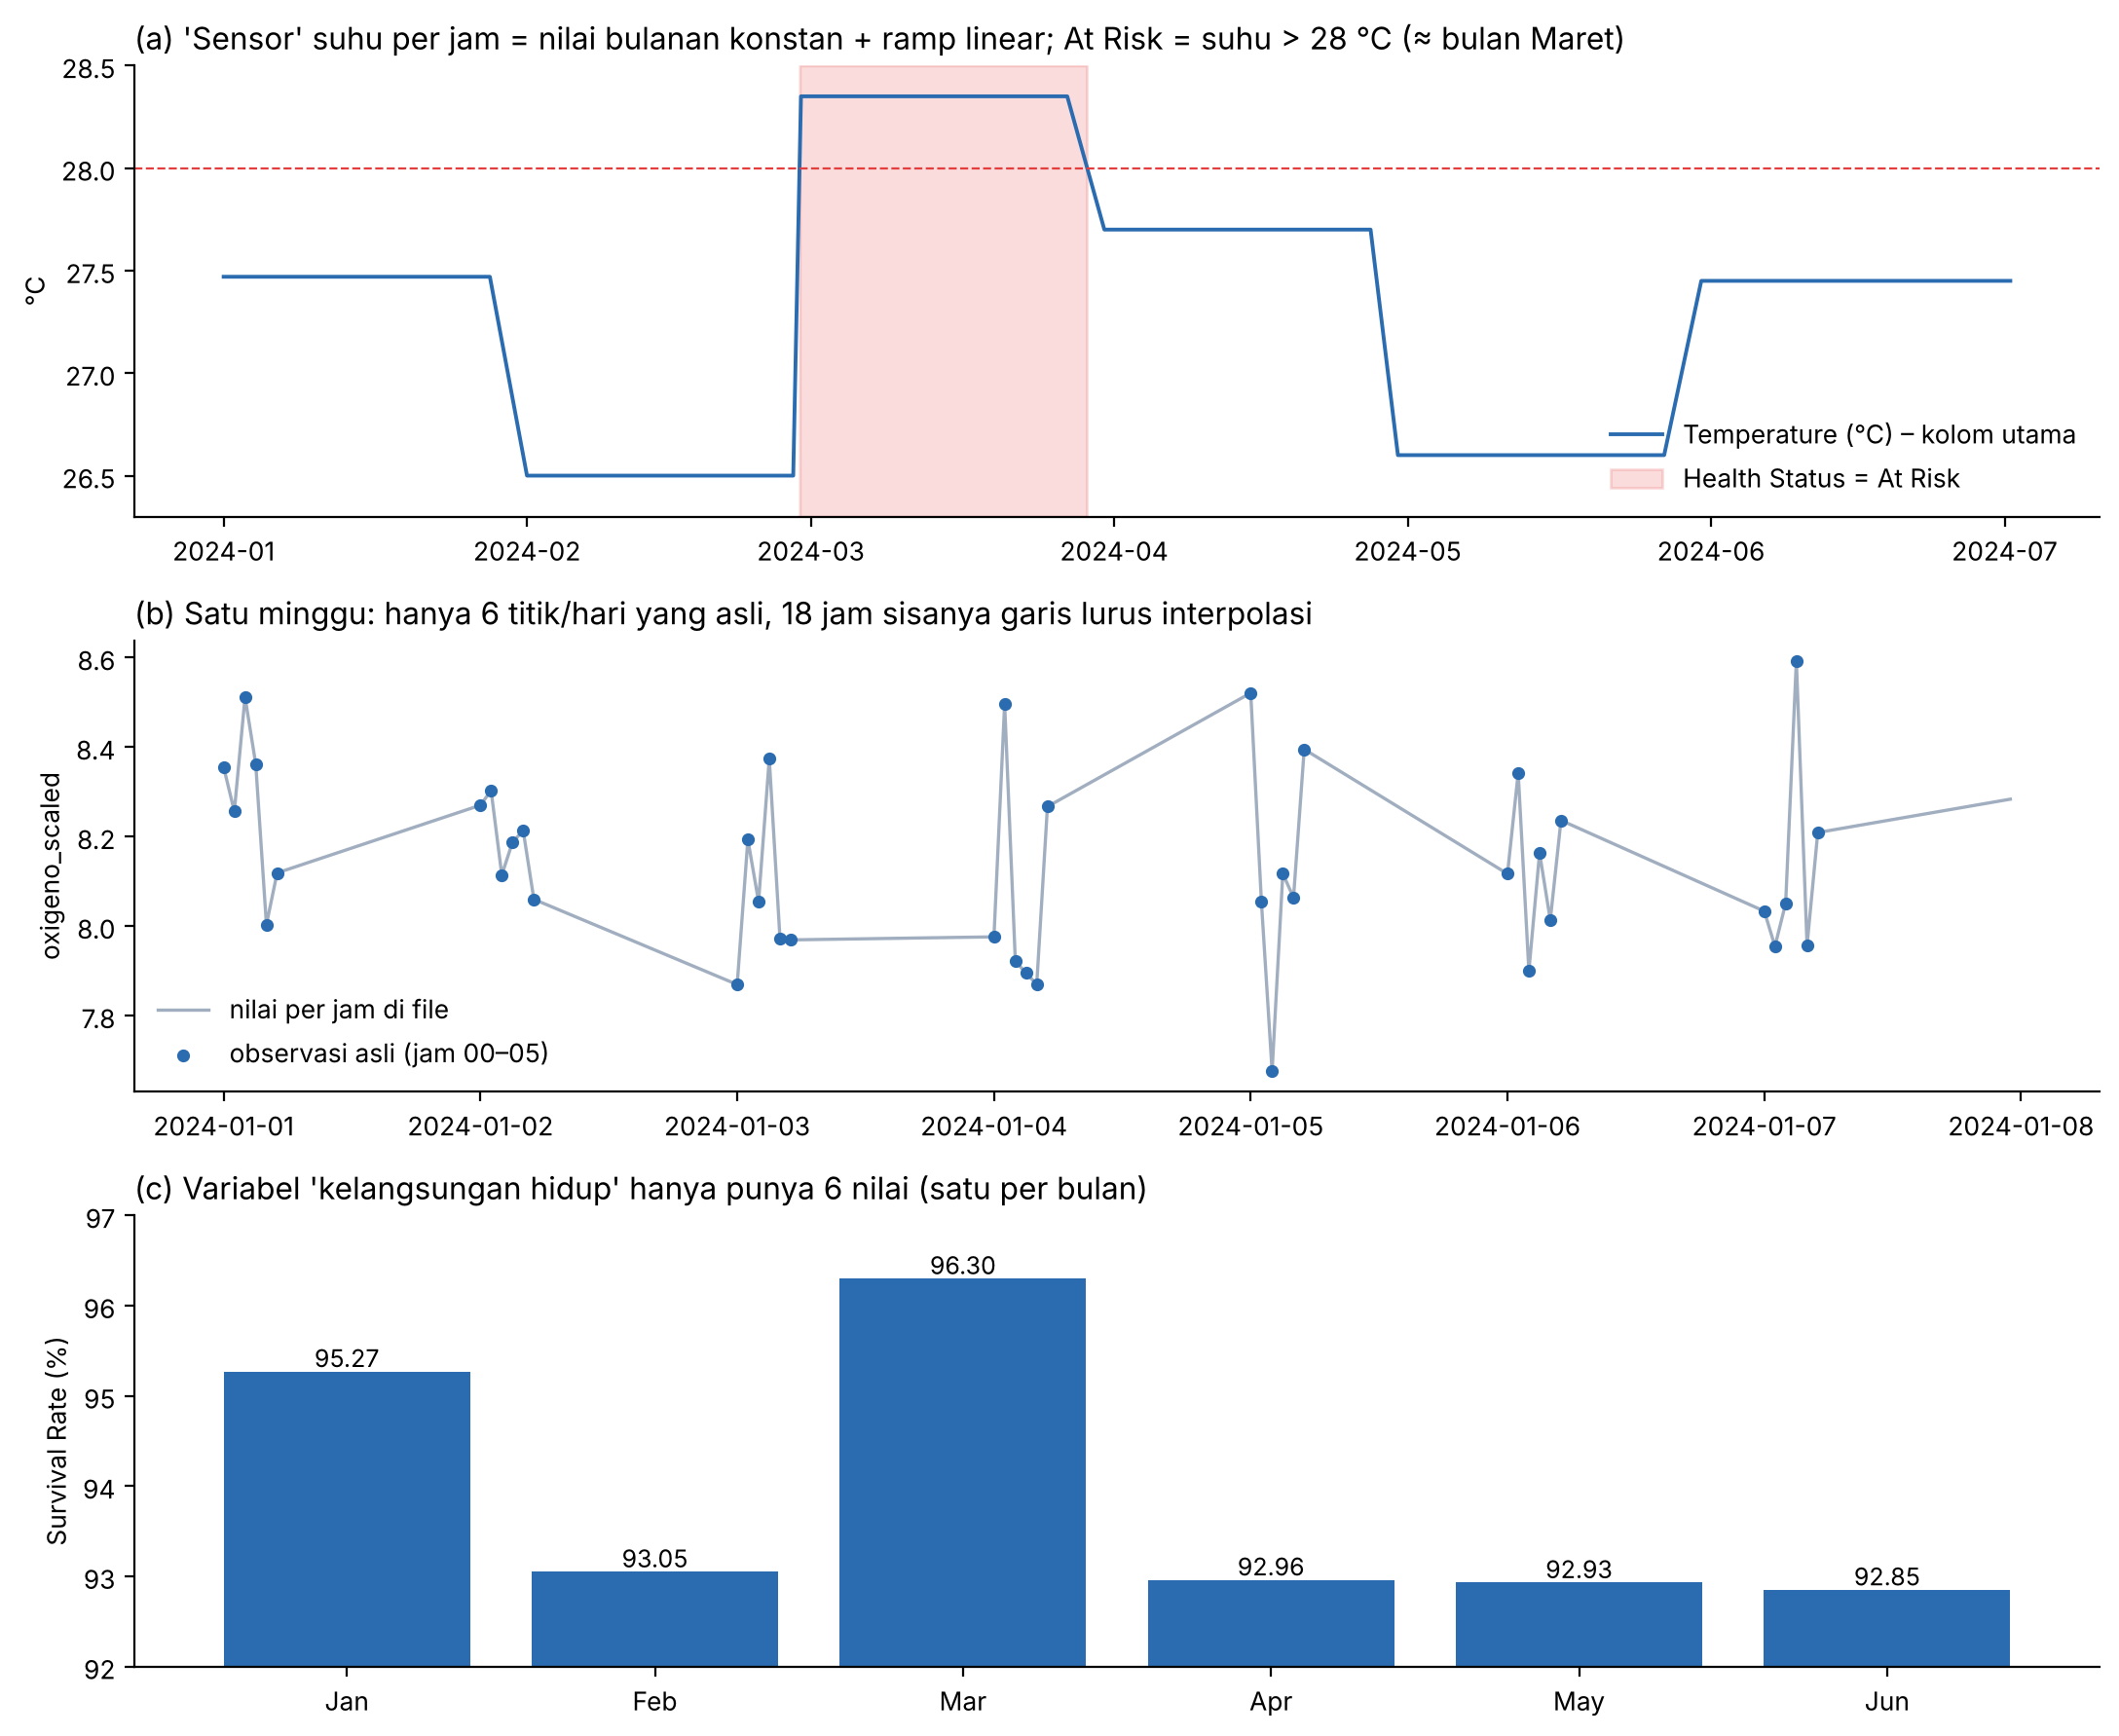

In [11]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9))
a = ax[0]
a.plot(df.Datetime, df["Temperature (°C)"], color="#2b6cb0", lw=1.4, label="Temperature (°C) – kolom utama")
a.fill_between(df.Datetime, 26.3, 28.5, where=hi, color="#e53e3e", alpha=0.18, label="Health Status = At Risk")
a.axhline(28, ls="--", color="#e53e3e", lw=0.8); a.set_ylim(26.3, 28.5); a.set_ylabel("°C"); a.legend(loc="lower right", frameon=False)
a.set_title("(a) 'Sensor' suhu per jam = nilai bulanan konstan + ramp linear; At Risk = suhu > 28 °C (≈ bulan Maret)", loc="left")
b = ax[1]
w = df[(df.Datetime >= "2024-01-01") & (df.Datetime < "2024-01-08")]
gw = w[isint(w.day) & isint(w.hour) & (w.hour <= 5)]
b.plot(w.Datetime, w.oxigeno_scaled, color="#a0aec0", lw=1.2, label="nilai per jam di file")
b.scatter(gw.Datetime, gw.oxigeno_scaled, color="#2b6cb0", s=14, zorder=3, label="observasi asli (jam 00–05)")
b.set_ylabel("oxigeno_scaled"); b.legend(frameon=False, loc="lower left")
b.set_title("(b) Satu minggu: hanya 6 titik/hari yang asli, 18 jam sisanya garis lurus interpolasi", loc="left")
c = ax[2]; labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
c.bar(labels, monthly["Survival Rate (%)"], color="#2b6cb0")
for i, v in enumerate(monthly["Survival Rate (%)"]): c.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
c.set_ylim(92, 97); c.set_ylabel("Survival Rate (%)")
c.set_title("(c) Variabel 'kelangsungan hidup' hanya punya 6 nilai (satu per bulan)", loc="left")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_audit.png", dpi=160); plt.show()
json.dump(audit, open(f"{OUT}/audit_results.json", "w"), indent=2, default=str)

**Kesimpulan audit:** hanya ±23% observasi yang asli; kolom sensor utama adalah nilai bulanan; `Health Status` = suhu bulanan > 28 °C (praktis = bulan Maret, justru bulan dengan survival tertinggi); `Low Oxygen Alert` selalu *Safe*; survival hanya 6 nilai.
Dataset ini **tidak cukup** untuk memprediksi kelangsungan hidup tilapia secara kredibel, sehingga dipakai sebagai **jangkar kalibrasi** untuk digital twin di bawah.

## 4. Digital twin kolam tilapia (v0)
Simulator per jam untuk banyak kolam (Monte-Carlo), dengan 4 lapisan:

| Lapisan | Isi |
|---|---|
| Lingkungan | suhu air (siklus harian, musim hujan/kemarau, gelombang panas), fitoplankton (bloom & die-off), DO (neraca massa: fotosintesis − respirasi + reaerasi + aerator), pH (mengikuti fotosintesis), turbiditas (limpasan hujan) |
| Manajemen | kepadatan tebar, aerator otomatis histeresis (ON < 4 mg/L, OFF > 6 mg/L) dan kerusakan aerator |
| Biologi | hazard kematian per jam dari DO, suhu, pH, dan stres kronis (penyakit, tertunda 48 jam) |
| Sensor IoT | noise, drift pH (kalibrasi ulang tiap 15 hari), fouling DO, spike, data hilang, gateway mati |

**Jangkar literatur (dicatat di `PARAMS`)**: TLM-24 jam DO 1,41 mg/L (lab) dan toleransi 0,1–0,5 mg/L dengan akses permukaan (FAO) → nilai efektif 0,8 mg/L (diuji sensitivitasnya nanti); rentang suhu optimal 19,5–32,1 °C; CTmax 41,25–44,5 °C; pH tidak letal ≥ 3,5, layak 5,5–9,0.
**Kalibrasi**: rata-rata bulanan suhu, pH, turbiditas Montería; latar kematian bulanan 3,5%.

In [12]:
import numpy as np, pandas as pd

PARAMS = {
    # --- calibration to Montería monthly means (Jan..Jun 2024) ---
    "T_month": [27.47, 26.50, 28.35, 27.70, 26.60, 27.45],
    "pH_month": [7.98, 7.34, 7.97, 7.91, 7.89, 7.88],
    "turb_month": [3.30, 2.79, 2.79, 3.98, 3.19, 3.71],
    "rain_prob_month": [0.10, 0.07, 0.10, 0.35, 0.55, 0.50],   # dry Dec–Mar, rainy Apr/May–Nov
    "heatwave_prob_month": [0.02, 0.03, 0.04, 0.02, 0.0, 0.0],  # hot season Feb–Apr
    # --- environment ---
    "T_diel_amp": (0.8, 1.6),            # °C, afternoon peak ~15:00
    "Pmax": (1.3, 1.9),                  # mg O2 L^-1 h^-1 at chl=1, full light
    "r_plankton": 0.16, "r_sed": 0.07,   # mg L^-1 h^-1 at 20 °C
    "r_fish_per_kgm3": 0.045,            # mg L^-1 h^-1 per kg fish m^-3 at 20 °C
    "theta": 1.07, "k_reaer": (0.03, 0.06),
    "pH_beta": 0.9, "pH_calib_offset": 0.17,                      # pH rise per unit relative O2 supersaturation
    # --- management ---
    "stock_density_kg_m3": (1.0, 3.5), "stock_density_noaer_kg_m3": (0.6, 1.6),
    "aerator_prob": 0.80, "aerator_on_below": 4.0, "aerator_off_above": 6.0,
    "aerator_kla": (0.25, 0.45), "aerator_fail_prob_day": 0.006, "aerator_fail_days": (1, 4),
    # --- biology (hazard per hour) ---
    "N0": 10000,
    "h0_month": 0.035,                   # background monthly mortality (Montería survival 92.9–96.3 %)
    "DO_TLM24_lab": 1.41,                # 24-h median tolerance limit, lab N2-bubbling (Magid & Babiker 1975)
    "DO_TLM24": 0.80,                    # effective pond value: surface access lets tilapia tolerate 0.1–0.5 mg/L (FAO ARAC/87/WP/10)
                                         # -> uncertain parameter, varied in sensitivity analysis (0.5–1.41)
    "DO_TLM_temp_slope": 0.15,           # mg/L per °C above 30 °C (heat lowers hypoxia tolerance)
    "DO_scale": 0.25,
    "T_lethal": 39.0, "T_scale": 0.8,    # acute upper lethal zone (CTmax 41–44.5 °C)
    "T_opt_hi": 32.1,                    # upper bound optimal range (19.5–32.1 °C)
    "pH_lethal_low": 3.5, "pH_ok": (5.5, 9.0),
    "stress_halflife_h": 72, "disease_lag_h": 48, "k_disease": 0.0015,
    # --- sensors ---
    "noise": {"T": 0.10, "DO": 0.15, "pH": 0.05, "turb_rel": 0.05},
    "pH_drift_per_h": (-0.0012, 0.0012), "DO_fouling_per_h": (-0.0015, 0.0),
    "recal_every_h": 15 * 24, "spike_prob": 0.002, "dropout_prob": 0.01,
    "outage_prob_day": 0.01, "outage_hours": (3, 24),
}


def do_sat(T):
    """Freshwater DO saturation (mg/L) at sea level."""
    return 14.652 - 0.41022 * T + 0.007991 * T**2 - 0.000077774 * T**3


def sig(x):
    return 1.0 / (1.0 + np.exp(-x))


def simulate_pond(pid, rng, P, start="2024-01-01", end="2024-07-01"):
    idx = pd.date_range(start, end, freq="h", inclusive="left")
    n = len(idx)
    hour = idx.hour.values
    day = (np.arange(n) // 24)
    nd = day.max() + 1
    mon = idx.month.values - 1

    u = lambda a: rng.uniform(*a)
    T_amp, Pmax, k_re = u(P["T_diel_amp"]), u(P["Pmax"]), u(P["k_reaer"])
    has_aer = rng.random() < P["aerator_prob"]
    # farms without aeration stock less (semi-intensive practice)
    dens = u(P["stock_density_kg_m3"]) if has_aer else u(P["stock_density_noaer_kg_m3"])
    kla = u(P["aerator_kla"]) if has_aer else 0.0

    # smooth monthly baselines (interpolate between month mid-points)
    # hours since start (unit-safe; pandas may store datetime64[us])
    t0 = idx[0]
    mid = np.array([(pd.Timestamp(f"2024-{m+1:02d}-15") - t0) / pd.Timedelta(hours=1) for m in range(6)])
    tv = np.arange(n, dtype=float)
    # calibration: compensate mean rain cooling / mean photosynthetic pH deficit so monthly means match Montería
    T_base = np.interp(tv, mid, np.array(P["T_month"]) + 0.8 * np.array(P["rain_prob_month"]))
    pH_base = np.interp(tv, mid, np.array(P["pH_month"]) + P["pH_calib_offset"] + 0.25 * np.array(P["rain_prob_month"]))
    turb_base = np.interp(tv, mid, P["turb_month"])
    mday = np.array([idx[d * 24].month - 1 for d in range(nd)])

    # daily weather: rain, cloud, heatwave (multi-day)
    rain = rng.random(nd) < np.array(P["rain_prob_month"])[mday]
    cloud = np.clip(np.where(rain, rng.uniform(0.25, 0.6, nd), rng.uniform(0.75, 1.0, nd)), 0, 1)
    heat = np.zeros(nd)
    d = 0
    while d < nd:
        if rng.random() < P["heatwave_prob_month"][mday[d]]:
            L = rng.integers(3, 8); amp = rng.uniform(1.5, 4.0)
            heat[d:d + L] = amp * np.sin(np.linspace(0.2, np.pi - 0.2, len(heat[d:d + L])))
            d += L
        d += 1
    T_anom = np.zeros(nd)
    for i in range(1, nd):
        T_anom[i] = 0.7 * T_anom[i - 1] + rng.normal(0, 0.35)
    T_day = T_anom + heat - 0.8 * rain
    T = T_base + T_day[day] + T_amp * np.sin(2 * np.pi * (hour - 9) / 24)

    # phytoplankton: mean-reverting with blooms and die-offs (die-off -> DO crash risk)
    chl = np.ones(nd)
    chl[0] = rng.uniform(0.8, 1.2)
    bloom_p = 0.008 + 0.008 * (dens - 1.0) / 2.5
    for i in range(1, nd):
        c = chl[i - 1] + 0.08 * (1.0 + 0.15 * (dens - 3) - chl[i - 1]) + rng.normal(0, 0.05)
        if rng.random() < bloom_p:
            c += rng.uniform(0.6, 1.4)                # bloom
        if chl[i - 1] > 1.8 and rng.random() < 0.035:
            c = rng.uniform(0.35, 0.6)                # bloom crash (die-off)
        chl[i] = np.clip(c, 0.15, 3.5)
    chl_h = chl[day]
    light = np.clip(np.sin(np.pi * (hour - 6) / 12), 0, None) * cloud[day]

    # aerator failures
    aer_fail = np.zeros(nd, bool)
    d = 0
    while d < nd:
        if has_aer and rng.random() < P["aerator_fail_prob_day"]:
            L = rng.integers(*P["aerator_fail_days"]); aer_fail[d:d + L] = True; d += L
        d += 1

    # --- DO mass balance (hourly Euler) + biology ---
    th = P["theta"]
    DO = np.zeros(n); aer = np.zeros(n, int)
    DO[0] = do_sat(T[0])
    N = np.zeros(n); deaths = np.zeros(n); haz = np.zeros(n); hcomp = np.zeros((n, 4))
    N_t = float(P["N0"])
    h0 = -np.log(1 - P["h0_month"]) / (30 * 24)
    a_stress = np.log(2) / P["stress_halflife_h"]
    S = 0.0; S_hist = np.zeros(n)
    pH_true = np.zeros(n)
    rain_h = rain[day]
    on = False
    for t in range(n):
        Tt = T[t]; sat = do_sat(Tt)
        biomass = dens * N_t / P["N0"]
        resp = (P["r_plankton"] * chl_h[t] + P["r_sed"] + P["r_fish_per_kgm3"] * biomass) * th ** (Tt - 20)
        prod = Pmax * chl_h[t] * light[t]
        prev = DO[t - 1] if t else DO[0]
        # hysteresis aerator control (the IoT actuator)
        if has_aer and not aer_fail[day[t]]:
            if prev < P["aerator_on_below"]: on = True
            elif prev > P["aerator_off_above"]: on = False
        else:
            on = False
        aer[t] = int(on)
        degas = 0.3 * max(0.0, prev - 1.6 * sat)          # bubble loss at strong supersaturation
        dDO = prod - resp + k_re * (sat - prev) + (kla * (sat - prev) if on else 0.0) - degas
        DOt = max(0.05, prev + dDO + rng.normal(0, 0.05))
        DO[t] = DOt
        # pH follows photosynthetic CO2 uptake (relative supersaturation)
        pH_true[t] = pH_base[t] + P["pH_beta"] * np.clip((DOt - sat) / sat, -0.8, 1.0) - (0.25 if rain_h[t] else 0.0)
        # ---- hazards ----
        tlm = P["DO_TLM24"] + P["DO_TLM_temp_slope"] * max(0.0, Tt - 30)
        lam24 = np.log(2) / 24
        h_do = 2 * lam24 * sig((tlm - DOt) / P["DO_scale"])
        h_T = 2 * lam24 * sig((Tt - P["T_lethal"]) / P["T_scale"])
        h_pH = 2 * lam24 * sig((P["pH_lethal_low"] - pH_true[t]) / 0.15)
        # chronic stress index (dimensionless), EWMA
        s_now = (max(0.0, (4.0 - DOt) / 4.0) + max(0.0, (Tt - P["T_opt_hi"]) / 4.0)
                 + max(0.0, P["pH_ok"][0] - pH_true[t]) / 1.5 + max(0.0, pH_true[t] - P["pH_ok"][1]) / 1.5)
        S = S * np.exp(-a_stress) + s_now * (1 - np.exp(-a_stress))
        S_hist[t] = S
        S_lag = S_hist[t - P["disease_lag_h"]] if t >= P["disease_lag_h"] else 0.0
        h_dis = P["k_disease"] * S_lag ** 1.5
        h = h0 + h_do + h_T + h_pH + h_dis
        haz[t] = h
        hcomp[t] = (h_do, h_T, h_pH, h_dis)
        dd = rng.binomial(int(N_t), 1 - np.exp(-h)) if N_t > 0 else 0
        N_t -= dd; deaths[t] = dd; N[t] = N_t

    turb = turb_base * (0.8 + 0.25 * chl_h)
    # rain run-off pulses decaying with tau ~ 24 h
    pulse = np.zeros(n)
    for t in range(1, n):
        add = rng.uniform(3, 20) if (rain_h[t] and hour[t] == 14) else 0.0
        pulse[t] = pulse[t - 1] * np.exp(-1 / 24) + add
    turb = turb + pulse

    # --- IoT sensor layer ---
    nz = P["noise"]
    recal = (np.arange(n) % P["recal_every_h"])
    pH_drift = u(P["pH_drift_per_h"]) * recal
    DO_foul = 1 + u(P["DO_fouling_per_h"]) * recal / 24
    s_T = T + rng.normal(0, nz["T"], n)
    s_DO = np.clip(DO * DO_foul + rng.normal(0, nz["DO"], n), 0, None)
    s_pH = pH_true + pH_drift + rng.normal(0, nz["pH"], n)
    s_turb = np.clip(turb * (1 + rng.normal(0, nz["turb_rel"], n)), 0, None)
    sens = {"T": s_T, "DO": s_DO, "pH": s_pH, "turb": s_turb}
    for k in sens:
        sp = rng.random(n) < P["spike_prob"]
        sens[k] = np.where(sp, sens[k] * rng.choice([0.0, 2.5], n), sens[k])
        drop = rng.random(n) < P["dropout_prob"]
        sens[k] = np.where(drop, np.nan, sens[k])
    outage = np.zeros(n, bool)                  # gateway outage -> all sensors missing
    for dd_ in np.where(rng.random(nd) < P["outage_prob_day"])[0]:
        s0 = dd_ * 24 + rng.integers(0, 24); outage[s0:s0 + rng.integers(*P["outage_hours"])] = True
    for k in sens:
        sens[k] = np.where(outage, np.nan, sens[k])

    return pd.DataFrame({
        "pond_id": pid, "datetime": idx,
        "sensor_temp_c": sens["T"], "sensor_do_mgl": sens["DO"], "sensor_ph": sens["pH"], "sensor_turb_ntu": sens["turb"],
        "aerator_on": aer, "rain_day": rain_h.astype(int),
        "true_temp_c": T, "true_do_mgl": DO, "true_ph": pH_true, "true_turb_ntu": turb, "chl_index": chl_h,
        "stress_index": S_hist, "hazard_per_h": haz,
        "h_do": hcomp[:, 0], "h_temp": hcomp[:, 1], "h_ph": hcomp[:, 2], "h_disease": hcomp[:, 3], "deaths": deaths, "alive": N,
        "stock_density_kg_m3": dens, "has_aerator": int(has_aer),
    })

### 4.1 Jalankan simulasi (200 kolam × 4.368 jam ≈ 15–30 detik)

In [13]:
N_PONDS, SEED = 200, 42
rng = np.random.default_rng(SEED)
sim = pd.concat([simulate_pond(i, rng, PARAMS) for i in range(N_PONDS)], ignore_index=True)
print(sim.shape)
sim.head()

(873600, 23)


,pond_id,datetime,sensor_temp_c,sensor_do_mgl,sensor_ph,sensor_turb_ntu,aerator_on,rain_day,true_temp_c,true_do_mgl,true_ph,true_turb_ntu,chl_index,stress_index,hazard_per_h,h_do,h_temp,h_ph,h_disease,deaths,alive,stock_density_kg_m3,has_aerator
0,0,2024-01-01 00:00:00,26.374545,7.631022,8.209295,3.823581,0,0,26.546499,7.417211,8.115900,3.458892,0.992597,0.0,0.000049,1.846592e-13,1.002387e-08,2.496005e-15,0.0,2.0,9998.0,1.235443,1
1,0,2024-01-01 01:00:00,26.350423,7.048972,8.141588,3.698782,0,0,26.320967,7.080393,8.074290,3.458892,0.992597,0.0,0.000049,7.103703e-13,7.561391e-09,3.293956e-15,0.0,0.0,9998.0,1.235443,1
2,0,2024-01-01 02:00:00,25.988662,6.862415,8.085026,3.404935,0,0,26.179192,6.810784,8.041789,3.458892,0.992597,0.0,0.000049,2.088541e-12,6.333394e-09,4.090888e-15,0.0,0.0,9998.0,1.235443,1
3,0,2024-01-01 03:00:00,26.147002,6.677641,8.048730,3.435221,0,0,26.130835,6.495122,8.005580,3.458892,0.992597,0.0,0.000049,7.382514e-12,5.961905e-09,5.207811e-15,0.0,0.0,9998.0,1.235443,1
4,0,2024-01-01 04:00:00,26.044067,6.271216,7.969383,3.401293,0,0,26.179192,6.135822,7.965799,3.458892,0.992597,0.0,0.000049,3.107225e-11,6.333394e-09,6.789412e-15,0.0,0.0,9998.0,1.235443,1


## 5. Validasi simulator
Cek: (a) pola DO harian sesuai literatur (minimum menjelang fajar, maksimum sore), (b) rata-rata bulanan suhu & pH vs Montería, (c) contoh kejadian kematian massal, (d) survival bulanan vs Montería.

In [14]:
d = sim.copy(); d["m"] = d.datetime.dt.month; d["h"] = d.datetime.dt.hour
MON = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
ref = {"T": PARAMS["T_month"], "pH": PARAMS["pH_month"], "surv": monthly["Survival Rate (%)"].round(2).tolist()}
gm = d.groupby(["pond_id", "m"]).agg(start=("alive", "first"), dead=("deaths", "sum")); gm["surv"] = 100 * (1 - gm.dead / gm.start)
val = {
    "sim_T_month": d.groupby("m").true_temp_c.mean().round(2).tolist(), "ref_T_month": ref["T"],
    "sim_pH_month": d.groupby("m").true_ph.mean().round(2).tolist(), "ref_pH_month": ref["pH"],
    "sim_surv_overall_mean": round(gm.surv.mean(), 2), "ref_surv_overall_mean": round(float(np.mean(ref["surv"])), 2),
    "pond_months_below_90pct": round((gm.surv < 90).mean(), 3),
    "DO_hour_min": int(d.groupby("h").true_do_mgl.mean().idxmin()), "DO_hour_max": int(d.groupby("h").true_do_mgl.mean().idxmax()),
    "DO_dawn_mean": round(d[d.h == 5].true_do_mgl.mean(), 2), "DO_15h_mean": round(d[d.h == 15].true_do_mgl.mean(), 2),
    "MAE_T_month": round(float(np.mean(np.abs(np.array(d.groupby('m').true_temp_c.mean()) - ref["T"]))), 3),
    "MAE_pH_month": round(float(np.mean(np.abs(np.array(d.groupby('m').true_ph.mean()) - ref["pH"]))), 3),
    "MAE_sensor_DO": round((d.sensor_do_mgl - d.true_do_mgl).abs().mean(), 3),
}
json.dump(val, open(f"{OUT}/sim_validation.json", "w"), indent=1)
pd.Series(val)

sim_T_month                [27.46, 27.07, 28.32, 27.74, 26.82, 27.37]
ref_T_month                   [27.47, 26.5, 28.35, 27.7, 26.6, 27.45]
sim_pH_month                     [7.94, 7.58, 7.96, 7.93, 7.87, 7.87]
ref_pH_month                     [7.98, 7.34, 7.97, 7.91, 7.89, 7.88]
sim_surv_overall_mean                                           93.61
ref_surv_overall_mean                                           93.89
pond_months_below_90pct                                         0.078
DO_hour_min                                                         6
DO_hour_max                                                        15
DO_dawn_mean                                                     4.75
DO_15h_mean                                                      8.94
MAE_T_month                                                     0.157
MAE_pH_month                                                    0.057
MAE_sensor_DO                                                   0.143
dtype: object

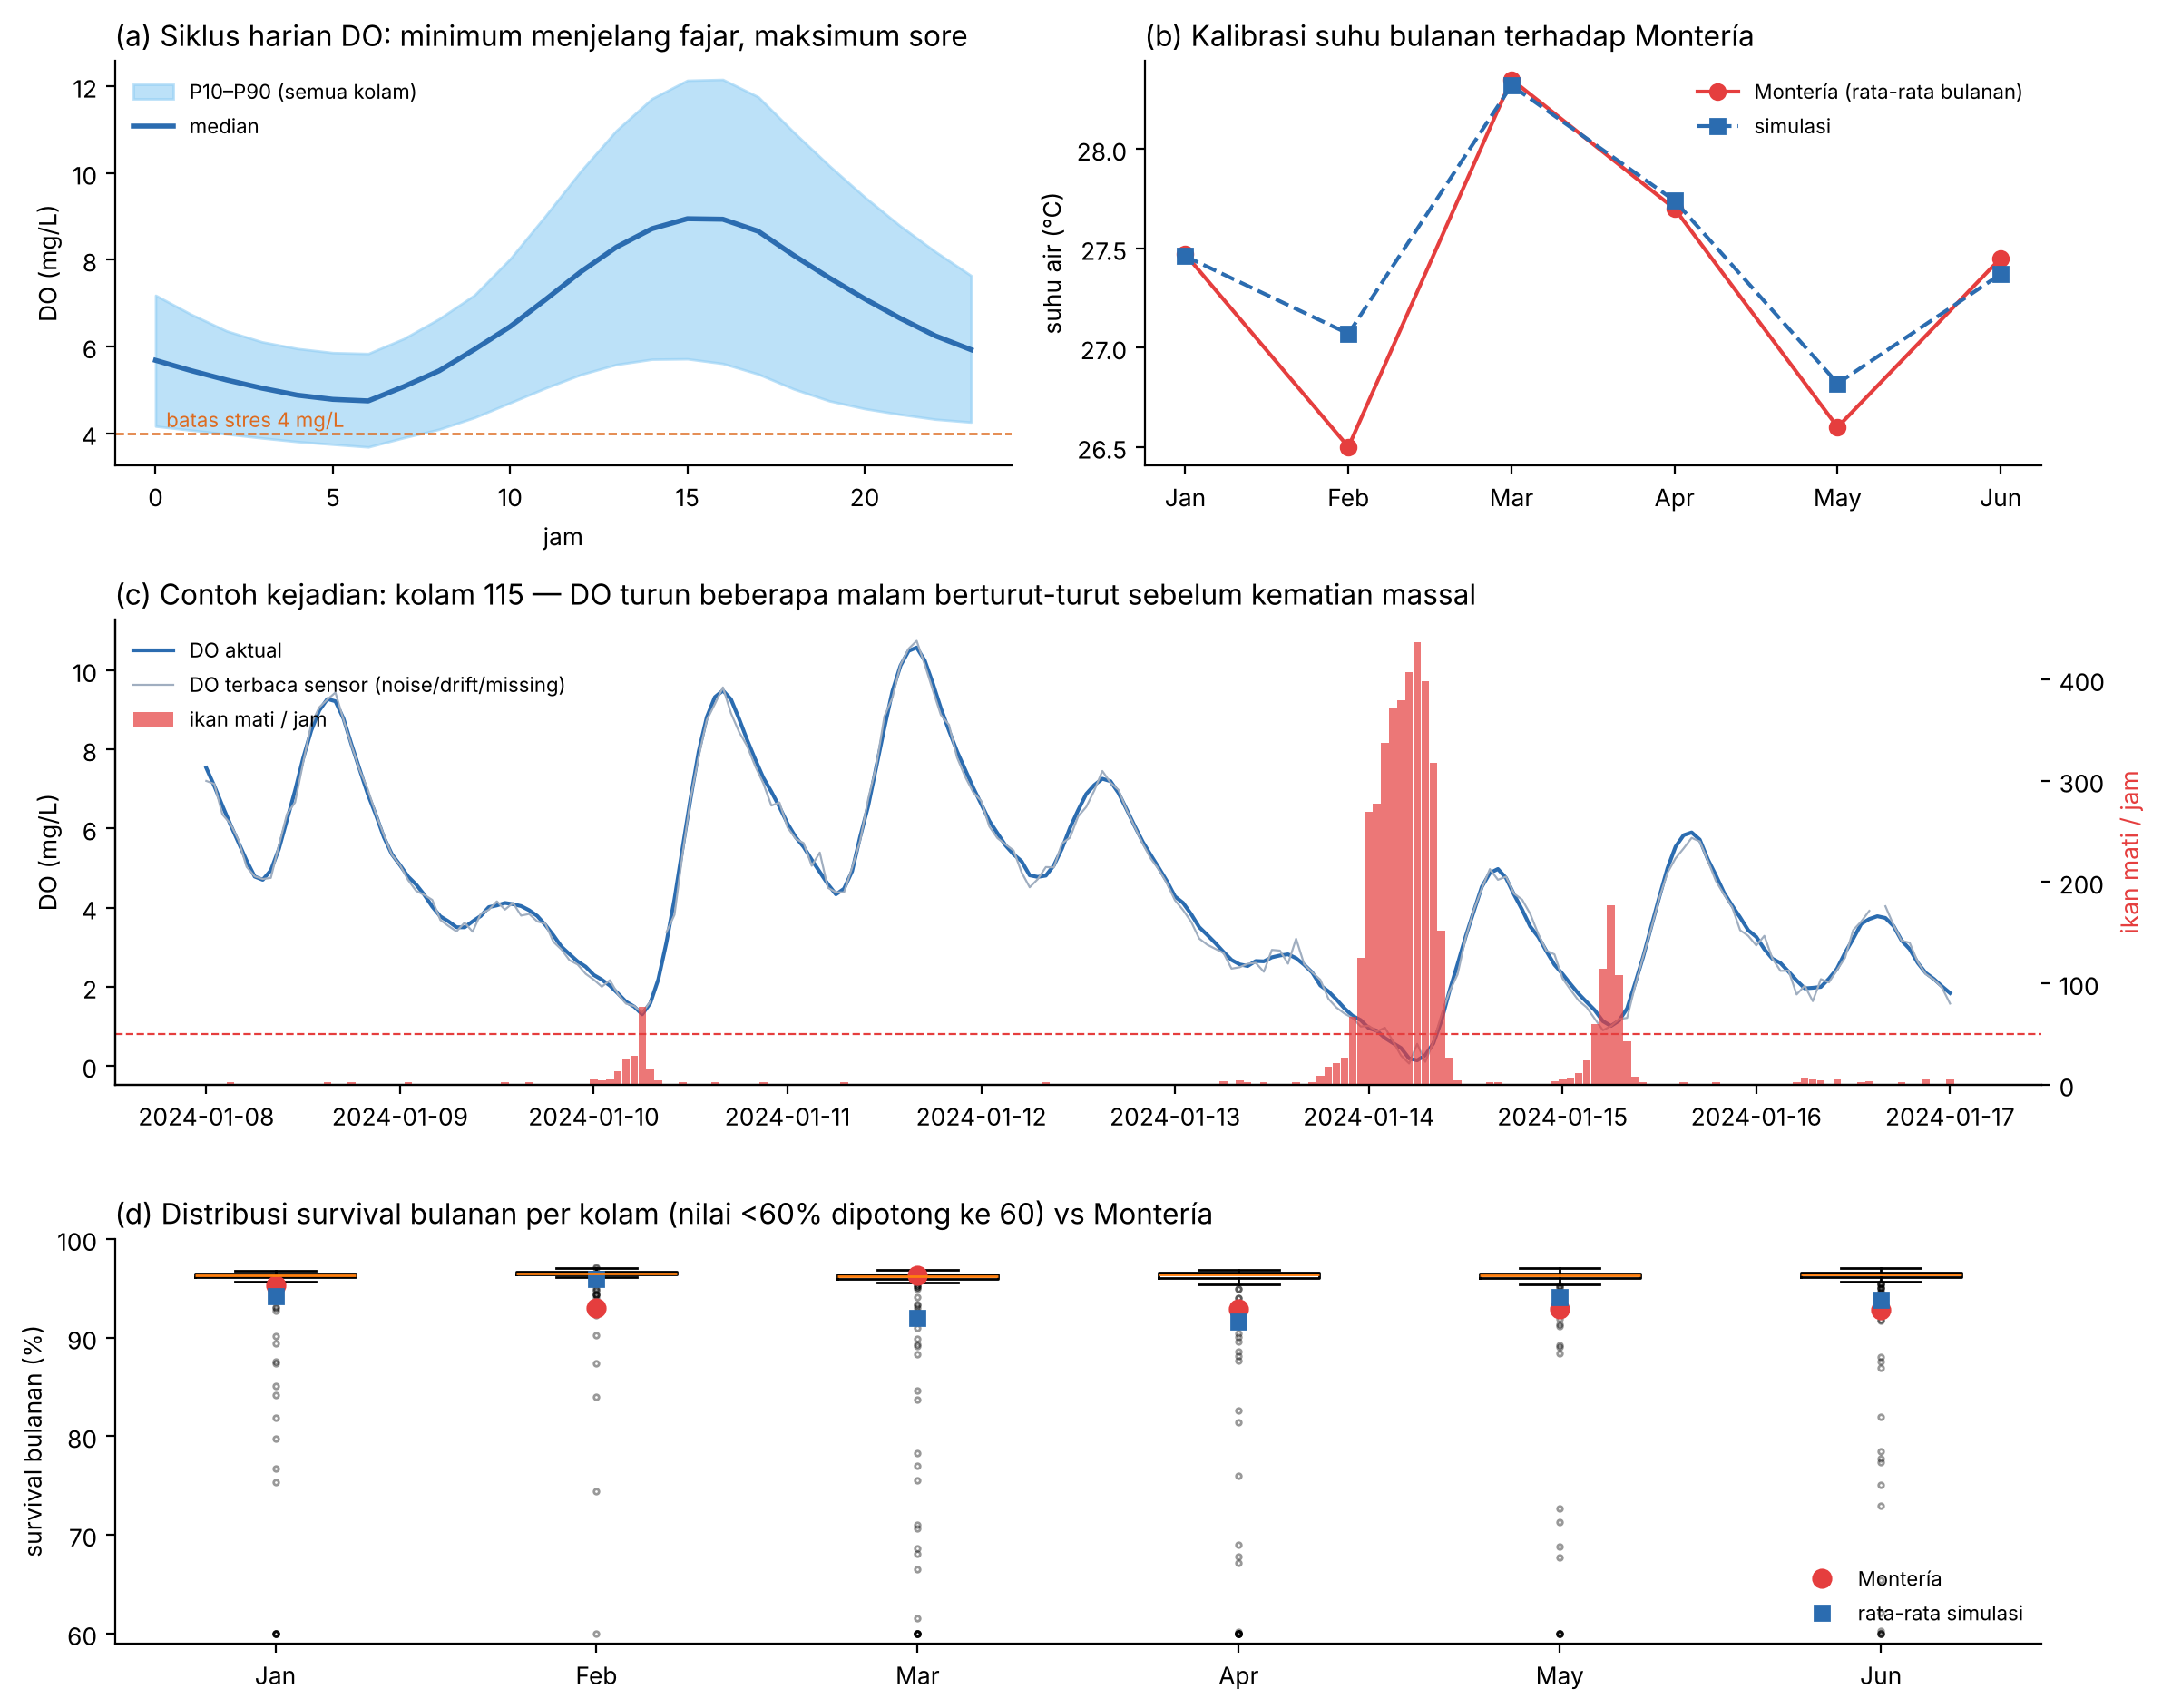

In [15]:
fig = plt.figure(figsize=(12, 9.5)); gs = fig.add_gridspec(3, 2, height_ratios=[1, 1.15, 1]); x = np.arange(6)
ax = fig.add_subplot(gs[0, 0])
q = d.groupby("h").true_do_mgl.quantile([0.1, 0.5, 0.9]).unstack()
ax.fill_between(q.index, q[0.1], q[0.9], color="#90cdf4", alpha=0.6, label="P10–P90 (semua kolam)")
ax.plot(q.index, q[0.5], color="#2b6cb0", lw=2, label="median")
ax.axhline(4, ls="--", color="#dd6b20", lw=0.9); ax.text(0.3, 4.15, "batas stres 4 mg/L", color="#dd6b20", fontsize=8)
ax.set_xlabel("jam"); ax.set_ylabel("DO (mg/L)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("(a) Siklus harian DO: minimum menjelang fajar, maksimum sore", loc="left")

ax = fig.add_subplot(gs[0, 1])
ax.plot(x, ref["T"], "o-", color="#e53e3e", label="Montería (rata-rata bulanan)")
ax.plot(x, val["sim_T_month"], "s--", color="#2b6cb0", label="simulasi")
ax.set_xticks(x, MON); ax.set_ylabel("suhu air (°C)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("(b) Kalibrasi suhu bulanan terhadap Montería", loc="left")

ax = fig.add_subplot(gs[1, :])
ev = d.groupby("pond_id").deaths.sum().sort_values(); pid = ev.index[int(len(ev) * 0.9)]
p = d[d.pond_id == pid]; worst = p.set_index("datetime").deaths.resample("D").sum().idxmax()
w = p[(p.datetime >= worst - pd.Timedelta(days=6)) & (p.datetime <= worst + pd.Timedelta(days=3))]
ax.plot(w.datetime, w.true_do_mgl, color="#2b6cb0", lw=1.5, label="DO aktual")
ax.plot(w.datetime, w.sensor_do_mgl, color="#a0aec0", lw=0.8, label="DO terbaca sensor (noise/drift/missing)")
ax.axhline(PARAMS["DO_TLM24"], ls="--", color="#e53e3e", lw=0.8); ax.set_ylabel("DO (mg/L)")
ax2 = ax.twinx(); ax2.bar(w.datetime, w.deaths, width=0.04, color="#e53e3e", alpha=0.7, label="ikan mati / jam")
ax2.set_ylabel("ikan mati / jam", color="#e53e3e"); ax2.spines["top"].set_visible(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8, loc="upper left")
ax.set_title(f"(c) Contoh kejadian: kolam {pid} — DO turun beberapa malam berturut-turut sebelum kematian massal", loc="left")

ax = fig.add_subplot(gs[2, :])
ax.boxplot([gm.xs(m, level="m").surv.clip(lower=60) for m in range(1, 7)], positions=x, widths=0.5,
           flierprops=dict(markersize=2, alpha=0.4))
ax.plot(x, ref["surv"], "o", color="#e53e3e", ms=7, label="Montería")
ax.plot(x, gm.surv.groupby("m").mean().values, "s", color="#2b6cb0", ms=6, label="rata-rata simulasi")
ax.set_xticks(x, MON); ax.set_ylabel("survival bulanan (%)"); ax.set_ylim(59, 100); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("(d) Distribusi survival bulanan per kolam (nilai <60% dipotong ke 60) vs Montería", loc="left")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_sim_validation.png", dpi=160); plt.show()

## 6. Label awal & simpan dataset sintetis
Label early warning: **kematian > 0,5% stok dalam 24 jam ke depan** (≈ 4× kematian latar). Horizon 6/12 jam dibuat di fase berikutnya.

In [16]:
fut24 = sim.groupby("pond_id").deaths.transform(lambda s: s[::-1].rolling(24, min_periods=24).sum()[::-1].shift(-1))
sim["y_excess_mort_24h"] = (fut24 / sim.alive.replace(0, np.nan) > 0.005).astype("Int8")
y = sim["y_excess_mort_24h"].fillna(0).astype(bool)
episodes = int((y & ~y.groupby(sim.pond_id).shift(1, fill_value=False)).sum())
print(f"Prevalensi label: {y.mean():.2%} | episode: {episodes} | kolam dengan kejadian: {sim.assign(y=y).groupby('pond_id').y.any().sum()}")
sim.to_csv(f"{OUT}/sim_ponds.csv.gz", index=False, compression="gzip")
json.dump(PARAMS, open(f"{OUT}/sim_params.json", "w"), indent=1)
print("Tersimpan di folder:", OUT, os.listdir(OUT))

Prevalensi label: 1.66% | episode: 574 | kolam dengan kejadian: 69


Tersimpan di folder: ../outputs ['sim_validation.json', 'audit_results.json', 'fig_sim_validation.png', 'sim_ponds.csv.gz', '.gitkeep', 'sim_params.json', 'fig_audit.png']
